# 07 — Final results on the test set
Validation'da en iyi kurulum seçilir ve **test seti sadece bir kez** değerlendirilir. Bu sayı modelin hiç görmediği veride beklenen performanstır.

In [1]:
# On Colab: mount Drive and work from the project's notebooks folder
import os, sys
if "google.colab" in sys.modules and not os.getcwd().endswith("notebooks"):
    from google.colab import drive
    drive.mount("/content/drive")
    %cd /content/drive/MyDrive/bone-age/notebooks
%run 00_common.ipynb

In [2]:
experiments = pd.read_json(OUTPUT_DIR / "experiments.json")
best = experiments.iloc[0]
print(f"Selected on validation: {best['setup']} (val MAE {best['val_mae']:.2f})")
res, metrics = evaluate(best["runs"], "test", bool(best["tta"]))
out_dir = OUTPUT_DIR / "test_results"
out_dir.mkdir(exist_ok=True)
res.to_csv(out_dir / "predictions.csv", index=False)
(out_dir / "metrics.json").write_text(json.dumps({"setup": best["setup"], **metrics}, indent=2))
print(f"TEST  MAE {metrics['mae']:.2f} mo | RMSE {metrics['rmse']:.2f} mo | R2 {metrics['r2']:.4f}")

Selected on validation: baseline_b0_384 + b0_512 + b3_384 + TTA (val MAE 6.26)


predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

TEST  MAE 6.54 mo | RMSE 8.80 mo | R2 0.9530


In [3]:
base = pd.read_csv(OUTPUT_DIR / "baselines.csv").set_index("split")
pd.DataFrame({"Test MAE (months)": {
    "Baseline: train mean": base.loc["test", "mean_baseline_mae"],
    "Baseline: mean per sex": base.loc["test", "sex_mean_baseline_mae"],
    f"Ours: {best['setup']}": metrics["mae"],
    "RSNA 2017 winner (official test set)": 4.27,
}}).round(2)

,Test MAE (months)
Baseline: train mean,33.28
Baseline: mean per sex,31.98
Ours: baseline_b0_384 + b0_512 + b3_384 + TTA,6.54
RSNA 2017 winner (official test set),4.27


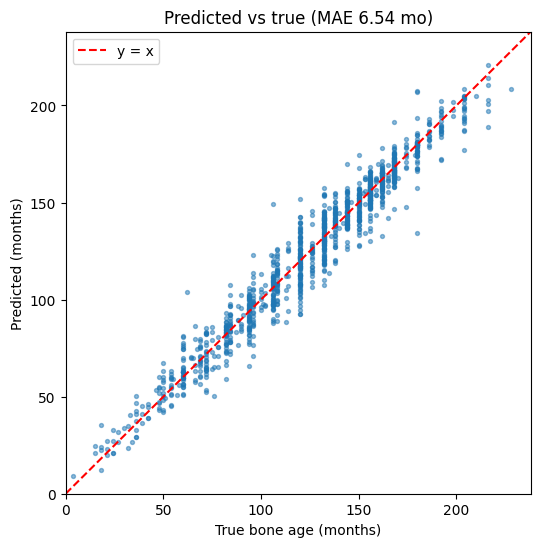

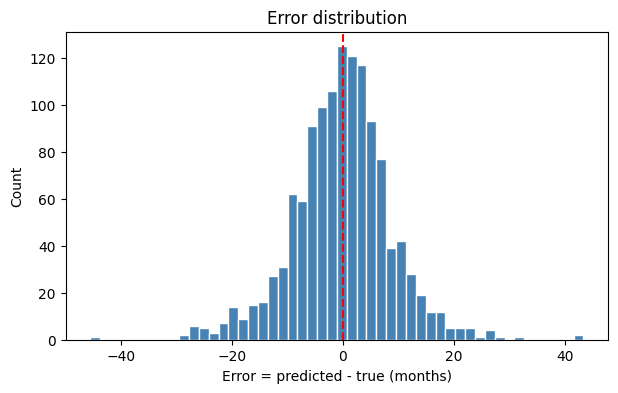

In [4]:
plot_results(res, out_dir)

In [5]:
by_age = res.groupby("age_group", observed=True)["abs_error"].agg(MAE="mean", n="size")
by_sex = res.groupby(res["male"].map({True: "male", False: "female"}))["abs_error"].agg(MAE="mean", n="size")
display(by_age.round(2), by_sex.round(2))

,MAE,n
age_group,,
0-5y,5.52,72
5-10y,7.11,357
10-15y,6.35,725
15+y,6.63,108


,MAE,n
male,,
female,6.81,579
male,6.32,683


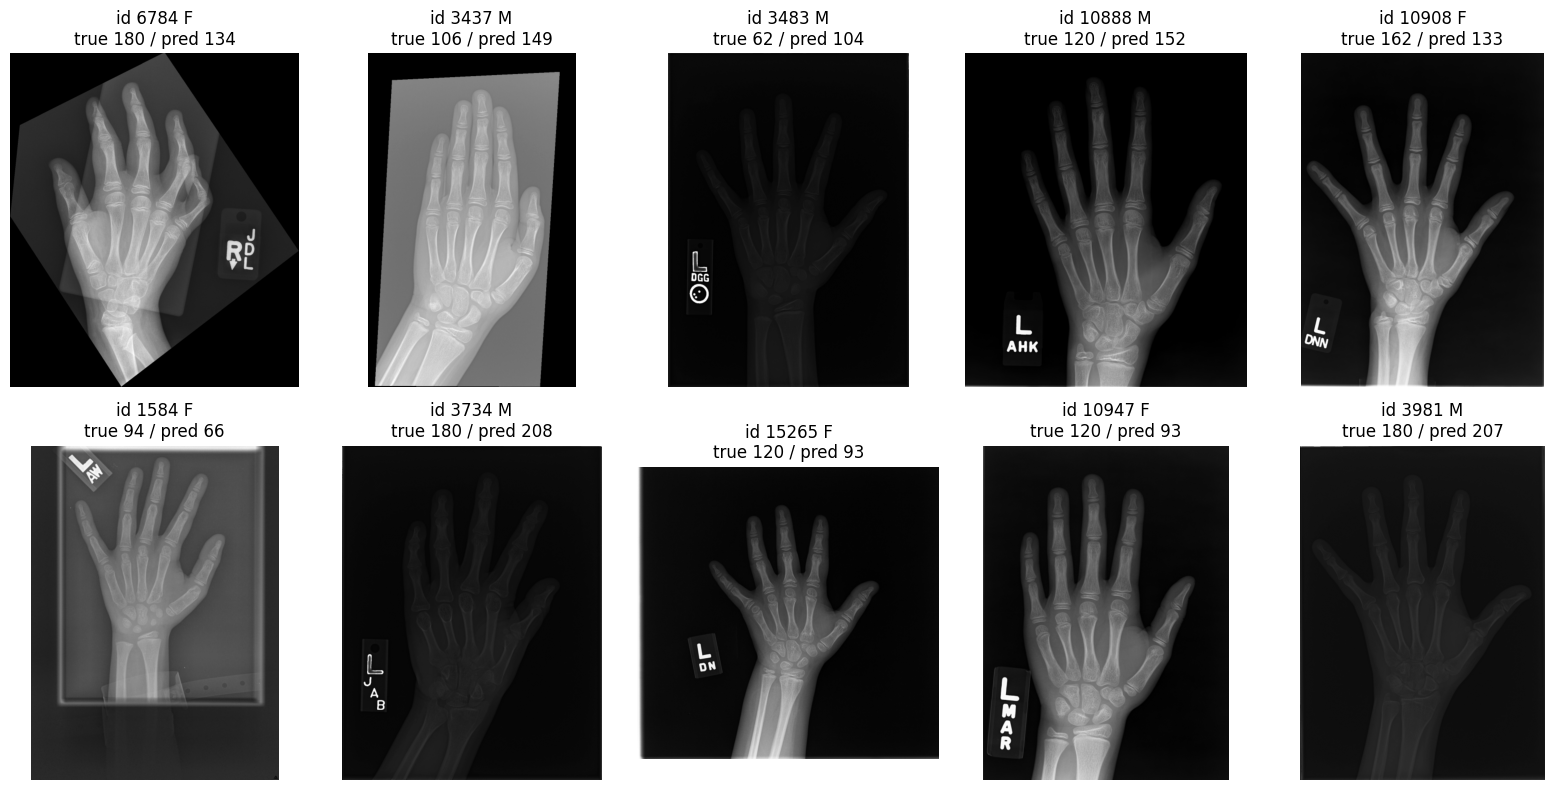

,id,male,boneage,pred,error
432,6784,False,180,134.500000,-45.5
173,3437,True,106,149.399994,43.4
176,3483,True,62,104.099998,42.1
802,10888,True,120,151.800003,31.8
805,10908,False,162,133.000000,-29.0
17,1584,False,94,65.699997,-28.3
196,3734,True,180,207.500000,27.5
1224,15265,False,120,92.599998,-27.4
811,10947,False,120,92.699997,-27.3
220,3981,True,180,207.199997,27.2


In [6]:
worst = show_worst(res, out_dir)
worst[["id", "male", "boneage", "pred", "error"]].round(1)

## En iyi sonuçlar (Best results)
Kayıtlı sonuçların özeti: validation'daki en iyi 5 kurulum ve her modelin en iyi epoch'u. Test sonucu yalnızca seçilen kurulum için vardır; diğer kurulumlar test setinde değerlendirilmedi.

In [ ]:
# Saved results only: nothing is predicted here, so the test set is not evaluated again
val = pd.read_json(OUTPUT_DIR / "experiments.json")
test = json.loads((OUTPUT_DIR / "test_results" / "metrics.json").read_text())

best_epochs = pd.DataFrame([
    {"model": run, "best epoch": log.loc[log["val_mae_months"].idxmin(), "epoch"], "epochs run": len(log),
     "best val MAE": log["val_mae_months"].min()}
    for run in ["baseline_b0_384", "b0_512", "b3_384", "scratch_cnn_cls"]
    for log in [pd.read_csv(OUTPUT_DIR / run / "log.csv")]
]).sort_values("best val MAE")

print(f"Best setup: {test['setup']}")
print(f"Validation MAE {val.iloc[0]['val_mae']:.2f} mo | Test MAE {test['mae']:.2f} mo | "
      f"Test RMSE {test['rmse']:.2f} mo | Test R2 {test['r2']:.4f}")
display(val[["setup", "val_mae", "val_rmse", "val_r2"]].head(5).round(3), best_epochs.round(2))

Best setup: baseline_b0_384 + b0_512 + b3_384 + TTA
Validation MAE 6.26 mo | Test MAE 6.54 mo | Test RMSE 8.80 mo | Test R2 0.9530


,setup,val_mae,val_rmse,val_r2
0,baseline_b0_384 + b0_512 + b3_384 + TTA,6.255,8.207,0.961
1,baseline_b0_384 + b0_512 + b3_384,6.300,8.269,0.960
2,baseline_b0_384 + TTA,6.549,8.528,0.958
3,b0_512 + TTA,6.616,8.602,0.957
4,baseline_b0_384,6.674,8.702,0.956


,model,best epoch,epochs run,best val MAE
0,baseline_b0_384,24,29,6.67
1,b0_512,15,20,6.72
2,b3_384,12,17,7.09
3,scratch_cnn_cls,30,30,7.81


## Yorum (Findings)
- **Test MAE 6.54 ay** (RMSE 8.80, R² 0.953). Val'daki 6.26'ya yakın → model seçimi val'a aşırı uymamış (overfit yok); fark normal örnekleme gürültüsü. Baseline'ın (33.3) ~5 katı daha iyi, "iyi sonuç (< 6 ay)" hedefine yakın; yarışma birincisinin (4.27, farklı/resmi test seti) ~2.3 ay gerisinde.
- **Scatter:** Tahminler y=x çizgisi etrafında dar bir bantta. Dikey "sütunlar" etiketlerin 6/12 ayın katlarına yuvarlanmasından geliyor (EDA'da görmüştük).
- **Yaş grubu:** En iyi 0–5 yaş (5.5 ay), en kötü 5–10 yaş (7.1 ay). Bu aralıkta kemik değişimleri hızlı ve radyolog etiketleri de daha belirsiz.
- **Cinsiyet:** Kızlarda 6.81, erkeklerde 6.32 ay — küçük bir fark; kızlarda ergenlik daha erken başladığı için aynı ayda daha fazla olgunluk çeşitliliği var.

**En kötü 10 tahmin — ortak örüntüler:**
1. **Çok karanlık / düşük kontrastlı görüntüler** (id 3483, 3734, 3981): Kemik detayları neredeyse görünmüyor. Model bu görüntülerde ortalamaya yakın ya da rastgele tahmin yapıyor. → Her görüntüye CLAHE/histogram eşitleme uygulamak (sadece augmentation olarak değil) yardımcı olabilir.
2. **Olağandışı pozisyon / el yapısı** (id 6784): ~35° dönük (augmentation sadece ±15°), parmaklar bükülü ve "R" (sağ el) işaretçisi var. Eğitim dağılımının dışında.
3. **Taranmış film / soluk gri** (id 1584, 3437): El, gri bir çerçeve içinde veya kırpılmış; kontrast düşük.
4. **Görünüşte normal görüntüler** (id 10888, 10908, 10947): Kalite iyi ama hata 27–32 ay. Bunlar büyük ihtimalle **etiket gürültüsü** (tek radyolog okuması) veya gerçekten atipik gelişim gösteren çocuklar.